In [ ]:
# We import the libraries we will be using
# 1. Pandas works to manipulate, analyze, clean and transform databases
import pandas as pd
# 2. Numpy is a fundamental open source library for scientific, data science and machine learning for Python
import numpy as np
# 3. Matplotlib is a low level data visualization library in Python    .Pyplot manages figures areas and labels
import matplotlib.pyplot as plt
# 4. Scipy library is used for advanced statistical analysis and probabilistic modelling
from scipy.stats import norm
from scipy import stats
# 5. Seaborn serves as a high level visualization library specialized in designing statistical graphs
import seaborn as sns

In [ ]:
# Import UCImlrepo package
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 

  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

# 1. Dataset Structure Inspection
The first step in the analysis is to understand the structure of the dataset.

This includes examining:

Number of observations
Number of variables
Data types
Presence of missing values
Summary statistics
Understanding the dataset before preprocessing helps identify potential data quality issues and informs subsequent machine learning decisions.

In [ ]:
print(X.shape)

(303, 13)


In [ ]:
print(y.shape)

(303, 1)


In [ ]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [ ]:
y.head()

,num
0,0
1,2
2,1
3,0
4,0


In [ ]:
X.info()


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


In [ ]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
df = pd.concat([X, y], axis=1)

In [ ]:
df.shape

(303, 14)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [ ]:
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [ ]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": round(df.isnull().mean()*100,2)
})

missing

,Missing Values,Percentage
age,0,0.00
sex,0,0.00
cp,0,0.00
trestbps,0,0.00
chol,0,0.00
fbs,0,0.00
restecg,0,0.00
thalach,0,0.00
exang,0,0.00
oldpeak,0,0.00


Findings
The dataset contains 303 observations and 14 variables.

Most variables are numeric and suitable for machine learning algorithms.

Preliminary inspection revealed a small number of missing values in the variables ca and thal.

Further preprocessing will be performed to address these missing observations before model training.

In [ ]:
df = pd.concat([X, y], axis=1)

print(df.shape)

display(df.head())

df.info()

display(df.describe())

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [ ]:
df = df.dropna()

In [ ]:
df['num'].value_counts().sort_index()

num
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

In [ ]:
df['num'].value_counts(normalize=True).sort_index()*100

num
0    53.872054
1    18.181818
2    11.784512
3    11.784512
4     4.377104
Name: proportion, dtype: float64

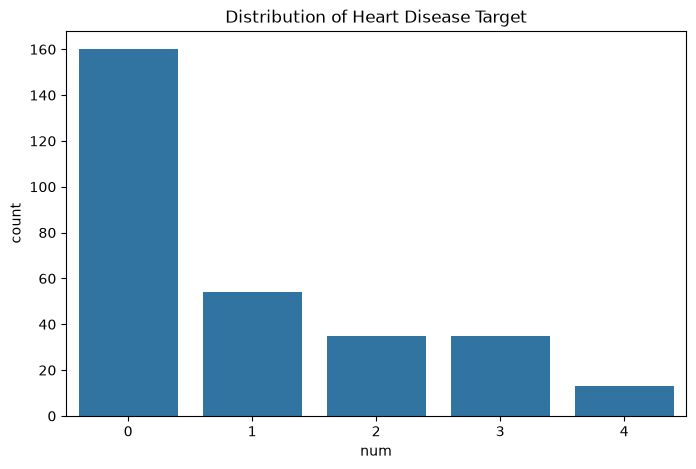

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x='num', data=df)
plt.title('Distribution of Heart Disease Target')
plt.show()

At this stage, the objective is not to build a predictive model.

The goal is to understand the characteristics of the dataset and identify any quality issues such as missing values or inconsistent data types.

Conducting this assessment before preprocessing reduces the risk of introducing data leakage or inappropriate transformations later in the project.

We are going to analyze the target variable **(num)** to decide whether our problem will be binary classification or multiclass classification, as that decision affects all the models we will build later.

Does it make more academic and statistical sense to predict 5 levels of disease, or simply to distinguish between 'disease' and 'no disease'?

# Target Variable Transformation
The original target variable contained five categories ranging from 0 to 4, representing different levels of heart disease severity.

For the purposes of this study, the target variable was transformed into a binary classification problem:

0 = No Heart Disease
1 = Presence of Heart Disease
This transformation simplifies interpretation, reduces class imbalance issues and aligns with the project's objective of predicting whether a patient presents heart disease.

# Binary Classification
The original target variable contains five levels of disease severity. However, several categories contain relatively few observations, creating class imbalance and increasing classification complexity. To improve model stability, interpretability and predictive performance, the target was transformed into a binary variable distinguishing between presence and absence of heart disease.

In [ ]:
# Convert target variable into binary classification

df['num'] = df['num'].apply(lambda x: 0 if x == 0 else 1)

# Verify transformation

df['num'].value_counts()

num
0    160
1    137
Name: count, dtype: int64

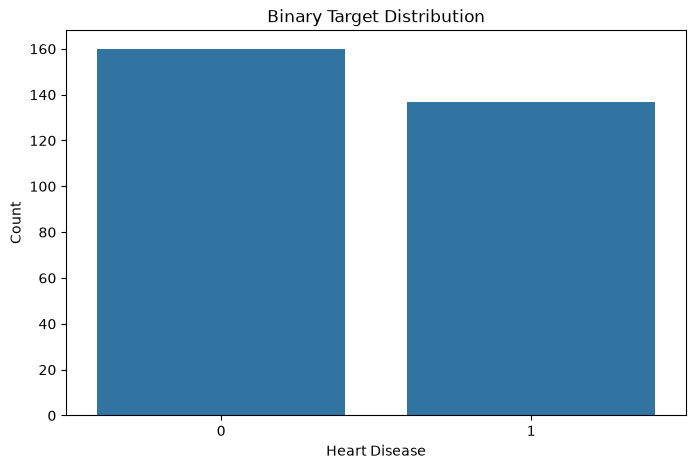

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(x='num', data=df)

plt.title('Binary Target Distribution')
plt.xlabel('Heart Disease')
plt.ylabel('Count')

plt.show()

Findings
After transforming the target variable, the dataset contains:

160 patients without heart disease.
137 patients with heart disease.
The resulting class distribution is relatively balanced, reducing the risk of model bias towards one class.

This balance is expected to improve the reliability of classification metrics such as Accuracy, Precision, Recall and F1-Score.

In [ ]:
df['num'].value_counts()

num
0    160
1    137
Name: count, dtype: int64

In [ ]:
df['num'].value_counts().sort_index()

num
0    160
1    137
Name: count, dtype: int64

In [ ]:
print("Before:", len(pd.concat([X,y], axis=1)))

df = pd.concat([X,y], axis=1).dropna()

print("After:", len(df))

Before: 303
After: 297


In [ ]:
original_rows = pd.concat([X,y], axis=1).shape[0]

clean_rows = df.shape[0]

print("Original:", original_rows)
print("After DropNA:", clean_rows)

print("Rows Removed:", original_rows-clean_rows)

print("% Removed:",
      round((original_rows-clean_rows)/original_rows*100,2))

Original: 303
After DropNA: 297
Rows Removed: 6
% Removed: 1.98


# Missing Values Treatment
A missing value assessment was conducted before the modelling phase.

The dataset originally contained 303 observations. Missing values were identified in a small number of records corresponding mainly to the variables ca and thal.

A complete-case analysis approach was selected using:

df = df.dropna()

This procedure removed only 6 observations, representing approximately 1.98% of the total dataset.

Given the very small proportion of missing data, row deletion was considered more appropriate than imputation because it avoids introducing artificial values while preserving nearly all available information.

The final dataset contained 297 observations and was considered sufficiently representative for subsequent exploratory analysis and machine learning modelling.

# EDA Exploratory Data Analysis

The objective of this stage is to understand the statistical characteristics of the variables prior to machine learning modelling.

The analysis focuses on:

Variable distributions
Central tendency measures
Dispersion
Potential outliers
Relationships with the target variable
Understanding these properties helps identify patterns, anomalies and potential preprocessing requirements before model development.

In [ ]:
#Identifying the types of data we have and check if it's really what it looks like.

print(df.dtypes)

print("\n")

for col in df.columns:
    print(col, "->", df[col].nunique(), "unique values")

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object


age -> 41 unique values
sex -> 2 unique values
cp -> 4 unique values
trestbps -> 50 unique values
chol -> 152 unique values
fbs -> 2 unique values
restecg -> 3 unique values
thalach -> 91 unique values
exang -> 2 unique values
oldpeak -> 40 unique values
slope -> 3 unique values
ca -> 4 unique values
thal -> 3 unique values
num -> 5 unique values


In [ ]:
numeric_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print(numeric_columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


In [ ]:
continuous_vars = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

In [ ]:
binary_vars = [
    'sex',
    'fbs',
    'exang'
]

In [ ]:
categorical_vars = [
    'cp',
    'restecg',
    'slope',
    'ca',
    'thal'
]

Numeric EDA


In [ ]:
df[continuous_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


In [ ]:
df[continuous_vars].skew()

age        -0.219775
trestbps    0.700070
chol        1.118096
thalach    -0.536540
oldpeak     1.247131
dtype: float64

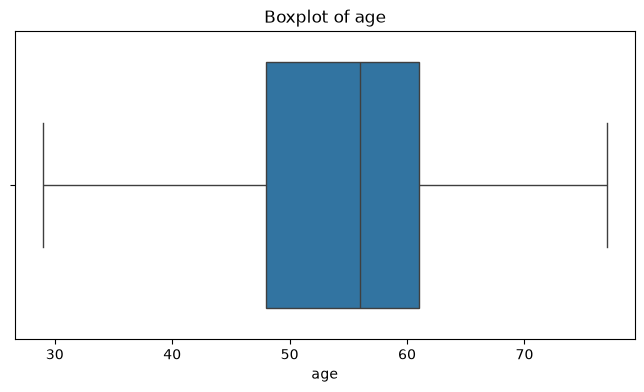

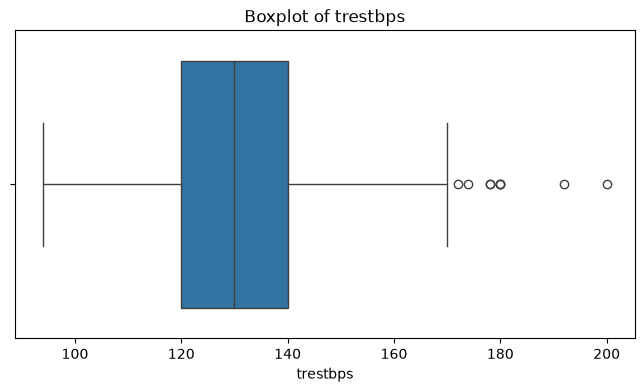

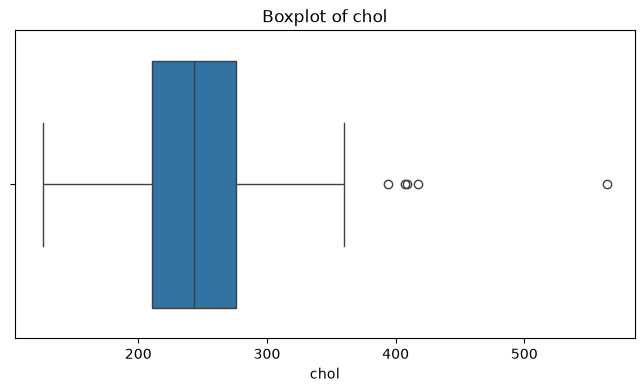

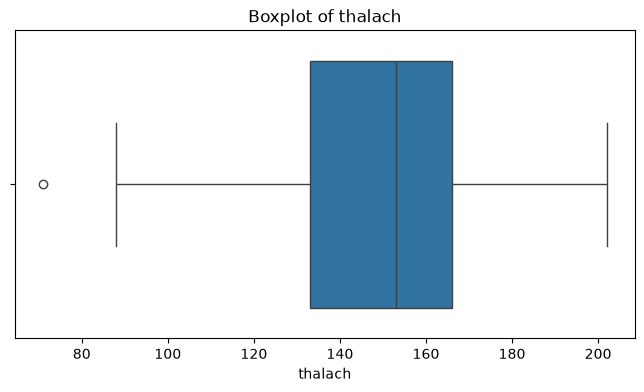

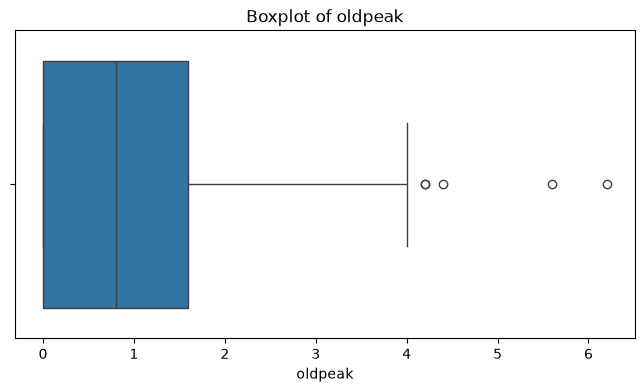

In [ ]:
for col in continuous_vars:

    plt.figure(figsize=(8,4))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')

    plt.show()

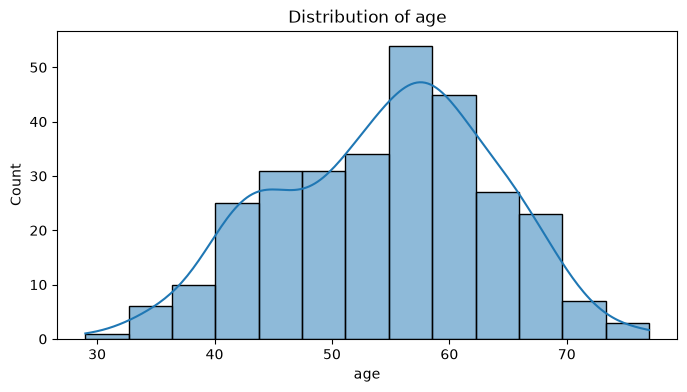

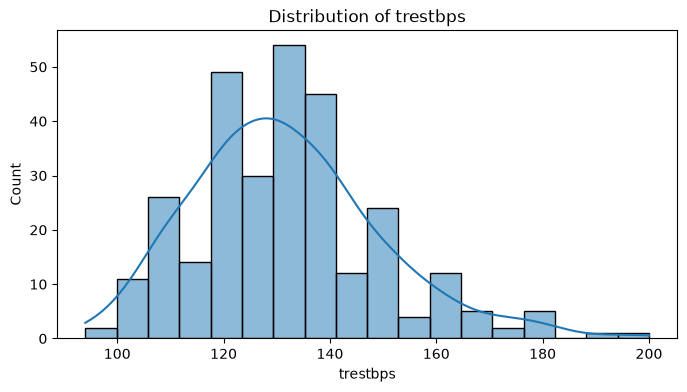

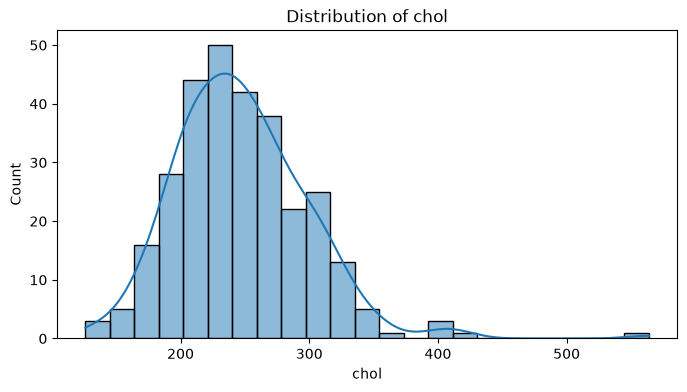

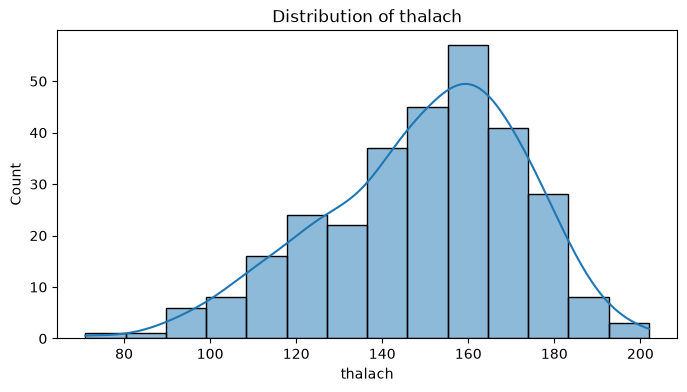

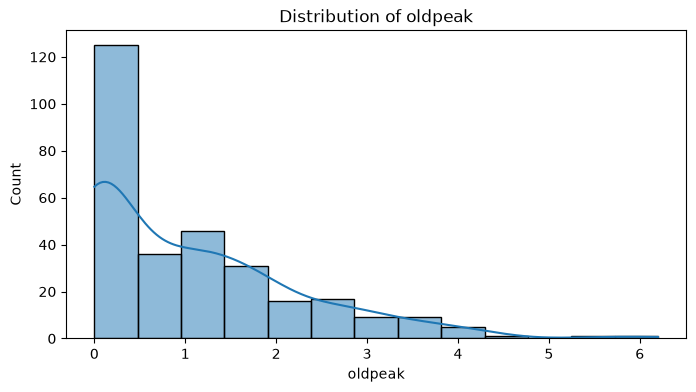

In [ ]:
numerical_cols = ['age','trestbps','chol','thalach','oldpeak']

for col in numerical_cols:

    plt.figure(figsize=(8,4))

    sns.histplot(df[col], kde=True)

    plt.title(f'Distribution of {col}')

    plt.show()

"La asimetría positiva observada en cholesterol (1.12) y oldpeak (1.24) fue posteriormente evaluada mediante boxplots para identificar posibles valores extremos."

# 3 Outlier Detection
Following the distribution analysis, boxplots were created for all continuous variables to identify potential outliers.

Outlier detection is important because extreme observations may influence summary statistics and machine learning algorithms. However, in healthcare datasets, outliers may represent genuine patient conditions rather than data entry errors.

Therefore, identified outliers were investigated before deciding whether any treatment was necessary.

**What are the most important features for predicting heart disease?**

Outlier Analysis
Boxplots were generated for all continuous variables to identify potential outliers.

Variables such as cholesterol, resting blood pressure and oldpeak presented several observations beyond the upper whisker, indicating the presence of extreme values.

These findings are consistent with the positive skewness previously observed in the distribution analysis.

No evidence of impossible or erroneous measurements was detected. Since the dataset represents real patient observations, these extreme values may contain clinically relevant information rather than measurement errors.

Consequently, no outlier removal procedure was applied and all observations were retained for subsequent analysis.

In [ ]:
df['num'].value_counts()
df['num'].nunique()

5

In [ ]:
df_binary = df.copy()

df_binary['num'] = df_binary['num'].apply(
    lambda x: 0 if x == 0 else 1
)

print(df_binary['num'].value_counts())

num
0    160
1    137
Name: count, dtype: int64


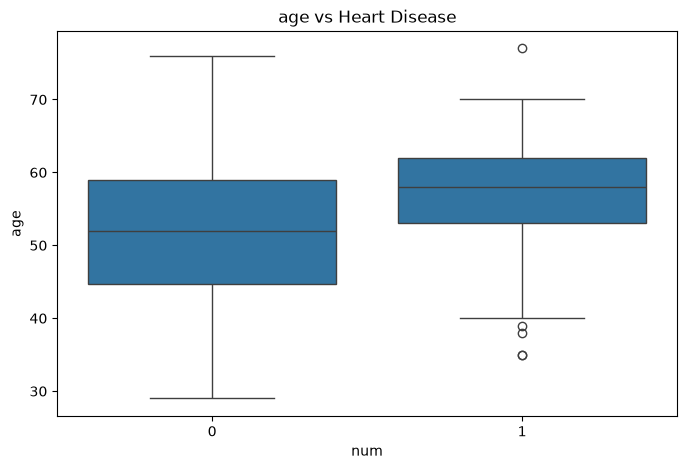

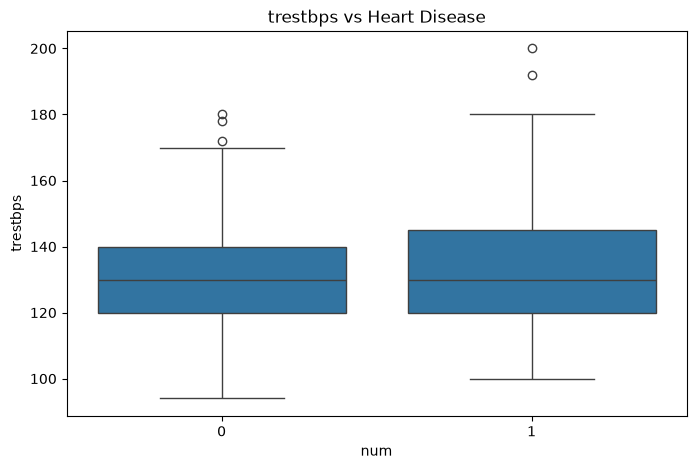

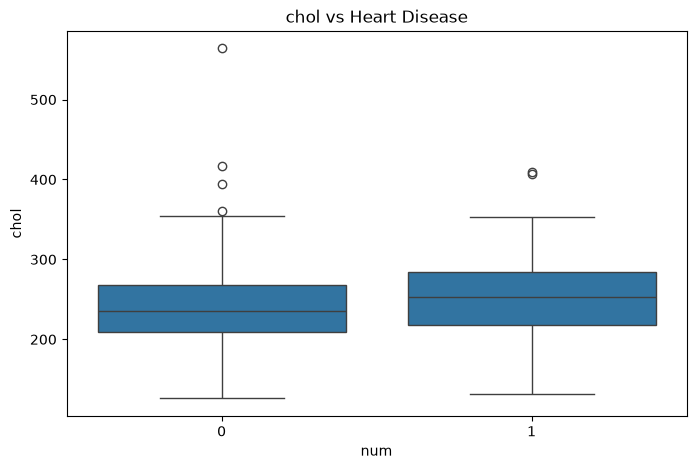

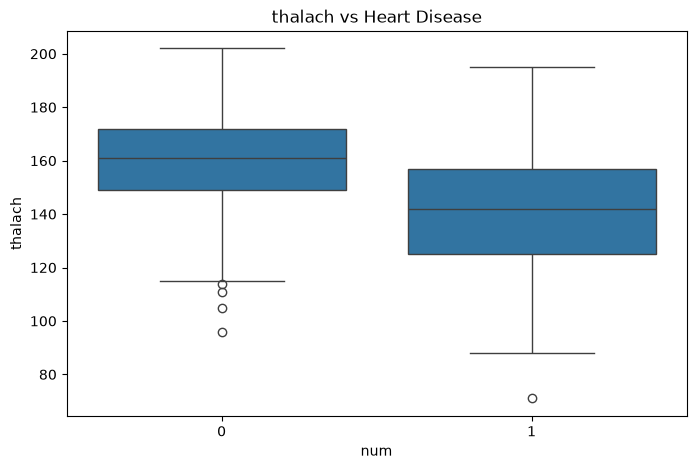

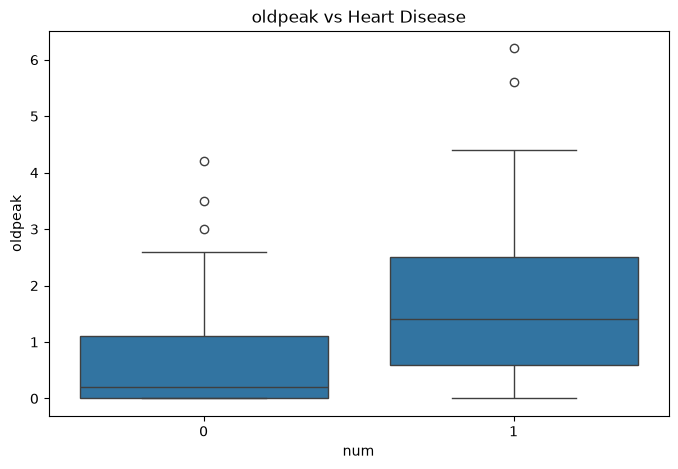

In [ ]:
continuous_vars = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

for col in continuous_vars:

    plt.figure(figsize=(8,5))

    sns.boxplot(
        x='num',
        y=col,
        data=df_binary
    )

    plt.title(f'{col} vs Heart Disease')

    plt.show()

The boxplot suggests that patients with heart disease tend to be older than patients without heart disease.

The median age appears higher in the disease group, indicating a potential association between age and the presence of heart disease.

Further statistical testing will be performed to evaluate whether this difference is statistically significant.

What are the most important features (X) for predicting Y?

Relationship Between Continuous Variables and Heart Disease
To investigate potential associations between patient characteristics and heart disease, boxplots were generated comparing the distributions of continuous variables across the target classes.

This visual analysis allows the identification of variables that exhibit different behaviour between patients with and without heart disease and provides an initial indication of their potential predictive value.

# Oldpeak vs Heart Disease
The distribution of oldpeak appears substantially higher among patients with heart disease.

The median value is notably greater in the disease group and the interquartile ranges show less overlap than observed for age.

This suggests that oldpeak may have stronger discriminative power for distinguishing between patients with and without heart disease.

Further statistical testing will be performed to assess the significance of this relationship.

¿La diferencia observada es estadísticamente significativa o podría haber ocurrido por azar?

¿Los pacientes con enfermedad cardíaca tienen valores de oldpeak diferentes a los pacientes sin enfermedad?

Hipotesis nula Oldpeak no está relacionado con la enfermedad.

Hipotesis alternativa Oldpeak sí está relacionado con la enfermedad.

In [ ]:
from scipy.stats import ttest_ind

healthy = df_binary[df_binary['num'] == 0]['oldpeak']

disease = df_binary[df_binary['num'] == 1]['oldpeak']

t_stat, p_value = ttest_ind(
    healthy,
    disease
)

print("T Statistic:", t_stat)
print("P-value:", p_value)

T Statistic: -8.042214149140525
P-value: 2.1597372771142582e-14


p < 0.05, we reject Ho.
There is a statistically significant difference in oldpeak values between patients with and without heart disease.

Statistical Analysis of Oldpeak
An independent samples t-test was conducted to compare the mean oldpeak values between patients with and without heart disease.

The analysis produced a t-statistic of -8.04 and a p-value of 2.16 × 10⁻¹⁴.

Since the p-value is substantially lower than the significance level of 0.05, the null hypothesis was rejected.

This result provides strong statistical evidence that oldpeak differs significantly between patients with and without heart disease, suggesting that it may be an important predictor in subsequent machine learning models.

What are the most important features for predicting heart disease?

In [ ]:
from scipy.stats import ttest_ind
import pandas as pd

continuous_vars = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

results = [] # We create a list 

for col in continuous_vars:

    healthy = df_binary[df_binary['num'] == 0][col]

    disease = df_binary[df_binary['num'] == 1][col]

    t_stat, p_value = ttest_ind(
        healthy,
        disease
    )

    results.append([
        col,
        round(t_stat, 4),
        p_value
    ])

ttest_results = pd.DataFrame(
    results,
    columns=[
        'Variable',
        'T-Statistic',
        'P-Value'
    ]
)

ttest_results = ttest_results.sort_values(
    by='P-Value'
)

print(ttest_results)

   Variable  T-Statistic       P-Value
4   oldpeak      -8.0422  2.159737e-14
3   thalach       8.0368  2.239715e-14
0       age      -4.0048  7.862868e-05
1  trestbps      -2.6679  8.054796e-03
2      chol      -1.3834  1.675878e-01


Statistical Comparison of Continuous Variables
Independent sample t-tests were conducted to compare the distributions of continuous variables between patients with and without heart disease.

The results indicate statistically significant differences for:

oldpeak (p < 0.001)
thalach (p < 0.001)
age (p < 0.001)
trestbps (p = 0.008)
These findings suggest that these variables may contribute useful information for predicting the presence of heart disease.

No statistically significant difference was observed for cholesterol levels (p = 0.168), indicating that cholesterol alone may have limited discriminatory power within this dataset.

In [ ]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_vars = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

results = []

for col in categorical_vars:

    contingency_table = pd.crosstab(
        df_binary[col],
        df_binary['num']
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    results.append([
        col,
        round(chi2, 4),
        p_value
    ])

chi_results = pd.DataFrame(
    results,
    columns=[
        'Variable',
        'Chi2 Statistic',
        'P-Value'
    ]
)

chi_results = chi_results.sort_values(
    by='P-Value'
)

print(chi_results)

  Variable  Chi2 Statistic       P-Value
7     thal         82.4601  1.241673e-18
1       cp         77.2758  1.178284e-16
6       ca         72.3005  1.372578e-15
4    exang         50.9426  9.510884e-13
5    slope         43.4732  3.630107e-10
0      sex         21.8516  2.945690e-06
3  restecg          9.5755  8.331151e-03
2      fbs          0.0000  1.000000e+00


"Which categorical variables have a statistically significant relationship with the presence of heart disease?"

Chi-Square Test of Independence
The null hypothesis (\(H_{0}\)) is: The categorical variable and heart disease are independent.
The alternative hypothesis (\(H_{1}\)) is: There is an association between the categorical variable and heart disease.

Chi-Square Test for Categorical Variables
Objective
The Chi-Square Test of Independence was applied to determine whether each categorical variable is associated with the presence of heart disease.

The null hypothesis states that the categorical variable and the target variable are independent.

A significance level of 0.05 was used.

Variables with p-values below 0.05 were considered statistically associated with heart disease.

Findings
The strongest associations with heart disease were observed for:

thal
cp
ca
exang
slope
These variables produced extremely small p-values, indicating strong statistical evidence of association with the target variable.

The variable fbs produced a p-value of 1.0000, suggesting no statistically significant association with heart disease within this dataset.

However, all variables were retained for subsequent machine learning modelling because statistical significance does not necessarily imply predictive importance.

# Feature Engineering / Preprocessing

##Data Preprocessing and Preparation Phase

1. Dataset Split (Train-Test Split)

What are we doing?
We are splitting our clean dataset (df_binary) into two independent subsets: one to train the Machine Learning models (80% of the data) and another to evaluate their final performance (20% of the data).

How are we doing it?
We use the train_test_split function from the sklearn.model_selection library. We use the stratify=y parameter to ensure that the proportion of patients with and without heart disease is exactly the same in both sets, and we define a random_state so that the results are reproducible.

Why are we doing it?
In statistics and Machine Learning, evaluating a model with the same data it was trained on is a serious methodological error (it causes overfitting). We need to simulate how the model will behave with new patients it has never seen before.

What are we doing it for?
To realistically validate the generalizable predictive power of our future models and avoid validation bias.

What response are we looking for by doing this?
We aim to obtain four clearly defined datasets: X_train (training features), X_test (testing features), y_train (training target variable), and y_test (testing target variable), ready to be processed in isolation.



In [ ]:
from sklearn.model_selection import train_test_split

# We define the predictor variables (X) and the target variable (y) using df_binary
X_data = df_binary.drop(columns=['num'])
y_data = df_binary['num']

# We split into Train (80%) and Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.2,
    stratify=y_data,
    random_state=42
)

print(f"Dimensions of training X: {X_train.shape}")
print(f"Dimensions of test X: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True) * 100}")
print(f"\nClass distribution in y_test:\n{y_test.value_counts(normalize=True) * 100}")

Dimensions of training X: (237, 13)
Dimensions of test X: (60, 13)
Class distribution in y_train:
num
0    54.008439
1    45.991561
Name: proportion, dtype: float64

Class distribution in y_test:
num
0    53.333333
1    46.666667
Name: proportion, dtype: float64


In [ ]:
# Always checking 

print(y_data.value_counts(normalize=True))

print(y_train.value_counts(normalize=True))

print(y_test.value_counts(normalize=True))

num
0    0.538721
1    0.461279
Name: proportion, dtype: float64
num
0    0.540084
1    0.459916
Name: proportion, dtype: float64
num
0    0.533333
1    0.466667
Name: proportion, dtype: float64


## - Standarscaler 
## - One-Hot Encoding

2. One-Hot Encoding of Categorical Variables and Scaling of Continuous Variables

What are we doing?
We are transforming our variables so that Machine Learning algorithms can process them optimally. We will convert non-ordinal categorical variables (cp, restecg, slope, thal) into binary vectors (One-Hot Encoding). We will scale the continuous variables (age, trestbps, chol, thalach, oldpeak) so that they have a mean of 0 and a standard deviation of 1.

How are we doing it?
We use ColumnTransformer from scikit-learn along with OneHotEncoder and StandardScaler. It is of vital importance to fit this transformer only on the training data (Train) and then transform both the Train and Test sets. The binary variables that are already in 0/1 format (sex, fbs, exang) will remain intact (passthrough).

Why are we doing it?
For categoricals: If we leave variables like chest pain type (cp) with numerical values from 1 to 4, the model will think that category 4 is statistically "greater" than 1, when in reality they represent distinct qualitative concepts.
For continuous variables: Variables like cholesterol (chol) have values in the hundreds, while oldpeak ranges from 0 to 6. The model could mistakenly believe that cholesterol is more important due to its numerical magnitude.
To avoid Data Leakage: If we scaled using the entire dataset, the mean and standard deviation of the test data would influence the training, ruining independent statistical validation.

What are we doing it for?
To ensure numerical stability, fast convergence in gradient-based algorithms, and to make sure all variables play under the same mathematical conditions.

What response are we looking for by doing this?
We aim to obtain two clean numerical matrices (X_train_preprocessed and X_test_preprocessed) ready to be fed directly into any Machine Learning model.



In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# We define the columns according to their treatment
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['cp', 'restecg', 'slope', 'thal']
# 'sex', 'fbs', 'exang', and 'ca' are already binary or structured numeric variables that do not require sparse category encoding in this step

# We create the preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ],
    remainder='passthrough'  # Keeps the columns we do not directly transform (such as sex, fbs, exang, ca)
)

# We fit with the training data and transform
X_train_preprocessed = preprocessor.fit_transform(X_train)

# We transform the test data using only the information learned from the training set
X_test_preprocessed = preprocessor.transform(X_test)

# We obtain the names of the new columns to visualize the result
encoded_cat_features = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(encoded_cat_features) + [col for col in X_train.columns if col not in num_cols + cat_cols]

# We recreate DataFrames for clear visual inspection
X_train_preprocessed_df = pd.DataFrame(X_train_preprocessed, columns=all_feature_names)
display(X_train_preprocessed_df.head())
print(f"\nNew dimensions after encoding and scaling: {X_train_preprocessed_df.shape}")

,age,trestbps,chol,thalach,oldpeak,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6.0,thal_7.0,sex,fbs,exang,ca
0,-0.085668,-0.462582,0.312737,-1.827448,0.967117,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
1,-0.973247,-1.749078,-0.987921,0.275439,-0.901878,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
2,-1.306090,-0.126974,1.236393,0.543892,0.712254,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,-0.862300,0.320503,0.143086,0.275439,-0.901878,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.358121,0.991719,0.388137,-1.737964,-0.222243,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0



New dimensions after encoding and scaling: (237, 18)


In [ ]:
print(X_train_preprocessed_df.info())

print(X_train_preprocessed_df.describe())

# Checking if the variables have mean =0 | std = 1 and see if the scalling work properly 

<class 'pandas.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        237 non-null    float64
 1   trestbps   237 non-null    float64
 2   chol       237 non-null    float64
 3   thalach    237 non-null    float64
 4   oldpeak    237 non-null    float64
 5   cp_2       237 non-null    float64
 6   cp_3       237 non-null    float64
 7   cp_4       237 non-null    float64
 8   restecg_1  237 non-null    float64
 9   restecg_2  237 non-null    float64
 10  slope_2    237 non-null    float64
 11  slope_3    237 non-null    float64
 12  thal_6.0   237 non-null    float64
 13  thal_7.0   237 non-null    float64
 14  sex        237 non-null    float64
 15  fbs        237 non-null    float64
 16  exang      237 non-null    float64
 17  ca         237 non-null    float64
dtypes: float64(18)
memory usage: 33.5 KB
None
                age      trestbps          chol       thala

In [ ]:
X_train_preprocessed_df.shape

(237, 18)

### The ca variable represents the number of major blood vessels observed via fluoroscopy. Its values (0, 1, 2, 3, 4) possess a natural order and a quantitative interpretation. There is a reasonable clinical relationship where a higher number of affected vessels may represent a greater level of cardiovascular involvement. Therefore, it is retained as a numerical ordinal variable instead of applying One-Hot Encoding.

# Baseline Model
## - Logistic Regression


#### ¿Qué tan bien puede predecirse la enfermedad cardíaca utilizando un modelo lineal simple?

3. Creation and Evaluation of the Baseline Model (Logistic Regression)
What are we doing?
We are building, training, and evaluating our first Machine Learning model: a Logistic Regression.

How are we doing it?
We import LogisticRegression from sklearn.linear_model and the evaluation metrics from sklearn.metrics (classification_report, confusion_matrix, accuracy_score).
We create the model object and fit it using the preprocessed training data (X_train_preprocessed) and the target variable (y_train).
We make predictions on the preprocessed test set (X_test_preprocessed).
We evaluate performance by comparing these predictions with the true labels (y_test) using a confusion matrix and a detailed classification report.

Why are we doing it?
In data science projects, we should never jump directly to complex models (such as neural networks or tree ensembles) without having a basic reference. Logistic Regression is ideal for its mathematical robustness, computational speed, and because it allows us to understand the direct impact of each variable's coefficients on the probability of having heart disease.

What are we doing it for?
To establish a performance baseline (reference metric). Any more complex model we develop in the following steps (such as Random Forest or SVM) must significantly outperform the results of this Logistic Regression to justify its use and complexity.

What response are we looking for by doing this?
We aim to understand the model's generalization capability through key metrics such as:

Accuracy: The total percentage of correct predictions.

Precision: Of the patients the model predicted as having the disease, how many actually had it (critical to avoid false positives).

Recall (Sensitivity): Of all the patients who actually had the disease, how many the model was able to detect (vital in medicine to avoid false negatives, which could put lives at risk).

F1-Score: The harmonic mean between precision and recall.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. We initialize the Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# 2. We train the model with the preprocessed training data
log_reg.fit(X_train_preprocessed, y_train)

# 3. We make predictions on the test set
y_pred = log_reg.predict(X_test_preprocessed)

# 4. We evaluate the results
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("=== BASELINE MODEL EVALUATION (LOGISTIC REGRESSION) ===\n")
print(f"Global Accuracy: {accuracy * 100:.2f}%\n")
print("Confusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

=== BASELINE MODEL EVALUATION (LOGISTIC REGRESSION) ===

Global Accuracy: 86.67%

Confusion Matrix:
[[29  3]
 [ 5 23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60



#### Logistic Regression Performance

The Logistic Regression model produced an overall accuracy of 86.67% on the test dataset.

The confusion matrix showed that the model correctly classified 29 of 32 healthy patients and 23 of 28 patients with heart disease.

The model achieved a precision of 88% and a recall of 82% for the heart disease class, indicating a strong ability to identify affected patients while maintaining a low false-positive rate.

The balanced F1-score of 85% suggests that the model provides a good trade-off between precision and recall and establishes a strong baseline for comparison with more advanced machine learning algorithms.

In [ ]:
from sklearn.metrics import roc_auc_score

from sklearn.metrics import RocCurveDisplay

roc_auc_score(y_test, log_reg.predict_proba(X_test_preprocessed)[:,1])

0.9497767857142857

## Baseline Model Findings: Logistic Regression

After completing data preprocessing, a Logistic Regression model was developed as the baseline classifier for heart disease prediction.

The model achieved:

Accuracy: 86.67%
Precision (Heart Disease): 88%
Recall (Heart Disease): 82%
F1-Score (Heart Disease): 85%
ROC-AUC: 0.95

The confusion matrix showed that the model correctly classified 52 of 60 patients, misclassifying only 3 healthy patients and 5 patients with heart disease.

These results indicate that the predictor variables contain a strong signal associated with heart disease and that Logistic Regression is capable of distinguishing between patients with and without disease with a high level of accuracy and discrimination ability.

The ROC-AUC score of 0.95 suggests excellent class separation performance, making Logistic Regression a strong baseline model for this dataset.

#### Why Compare with Random Forest and SVM?

Although Logistic Regression produced strong results, it assumes a relatively linear relationship between the predictor variables and the target outcome.

To verify whether more complex algorithms can capture additional patterns in the data, two alternative classifiers were evaluated:

Random Forest, which can model complex non-linear relationships using an ensemble of decision trees.
Support Vector Machine (SVM), which can identify optimal decision boundaries and handle both linear and non-linear classification problems.

Both models were optimized using GridSearchCV with 5-fold Stratified Cross-Validation to ensure a fair and robust comparison.

The objective is to determine whether these more sophisticated models can outperform the baseline Logistic Regression in terms of predictive performance, particularly regarding Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

### ** 4 Entrenamiento, Optimización (Hyperparameter Tuning) y Validación Cruzada de Modelos Clasificadores (Random Forest y SVM)
¿Qué estamos haciendo?

Estamos creando y optimizando de forma automática dos modelos clasificadores adicionales: un bosque aleatorio (Random Forest) y una máquina de vectores de soporte (Support Vector Machine o SVM), buscando sus mejores hiperparámetros estadísticos.
¿Cómo lo estamos haciendo?

Importamos GridSearchCV y StratifiedKFold de sklearn.model_selection para estructurar la validación cruzada robusta sin alterar la proporción de clases de nuestro target.
Definimos una grilla de parámetros (param_grid) para explorar distintas configuraciones: para Random Forest (número de árboles, profundidad máxima) y para SVM (tipo de kernel, parámetro de regularización C, coeficiente gamma).
Usamos GridSearchCV para entrenar decenas de combinaciones mediante validación cruzada estratificada de 5 divisiones (5-Fold CV).
Evaluamos de manera independiente los modelos ganadores utilizando el conjunto de prueba (X_test_preprocessed).
¿Por qué lo estamos haciendo?

Rúbrica: Cumplimos directamente con los requerimientos 'b' y 'd' de tu asignación (desarrollar dos modelos, optimizar hiperparámetros y usar validación cruzada).
Metodología: Los hiperparámetros por defecto de las librerías rara vez extraen el potencial real de un modelo. Buscarlos sistemáticamente previene el subajuste (underfitting) y el sobreajuste (overfitting).
¿Para qué lo estamos haciendo?
Para entrenar la mejor versión matemática de cada modelo en el conjunto de entrenamiento, garantizando mediante validación cruzada que las métricas obtenidas son representativas del comportamiento real del algoritmo en la práctica clínica.
¿Qué respuesta buscamos al hacerlo?
Buscamos identificar la mejor combinación de hiperparámetros para cada algoritmo, así como obtener sus predicciones optimizadas para compararlas con nuestro modelo base de Regresión Logística.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# We define the stratified cross-validation scheme (5 folds)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- MODEL 1: RANDOM FOREST ---
rf_model = RandomForestClassifier(random_state=42)
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)
grid_rf.fit(X_train_preprocessed, y_train)

best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_preprocessed)

# --- MODEL 2: SUPPORT VECTOR MACHINE (SVM) ---
svm_model = SVC(random_state=42, probability=True)
svm_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'sigmoid'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    estimator=svm_model,
    param_grid=svm_params,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)
grid_svm.fit(X_train_preprocessed, y_train)

best_svm = grid_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_preprocessed)

# --- PRINTING RESULTS AND BEST HYPERPARAMETERS ---
print("=== OPTIMIZATION AND CROSS-VALIDATION COMPLETED ===\n")
print("-> BEST RANDOM FOREST CONFIGURATION:")
print(grid_rf.best_params_)
print(f"Test Accuracy with Random Forest: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")

print("-> BEST SVM CONFIGURATION:")
print(grid_svm.best_params_)
print(f"Test Accuracy with SVM: {accuracy_score(y_test, y_pred_svm) * 100:.2f}%")

C:\Users\35383\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== OPTIMIZATION AND CROSS-VALIDATION COMPLETED ===

-> BEST RANDOM FOREST CONFIGURATION:
{'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}
Test Accuracy with Random Forest: 80.00%

-> BEST SVM CONFIGURATION:
{'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Test Accuracy with SVM: 86.67%


### Model Comparison Overview
Following the strong performance obtained with Logistic Regression (Accuracy = 86.67%, ROC-AUC = 0.95), two additional machine learning algorithms were optimized using GridSearchCV and Stratified 5-Fold Cross-Validation: Random Forest and Support Vector Machine (SVM).

The optimized Random Forest achieved an accuracy of 80.00%, while the optimized SVM achieved an accuracy of 86.67%, matching the Logistic Regression baseline.

Interestingly, the best-performing SVM used a linear kernel, suggesting that the relationship between the predictor variables and heart disease may be largely linear. Furthermore, the inability of Random Forest to outperform Logistic Regression indicates that more complex non-linear models do not provide substantial predictive advantages for this dataset.

To determine the final model, further comparison should be conducted using Precision, Recall, F1-Score, and ROC-AUC, with particular attention paid to Recall, given the clinical importance of correctly identifying patients with heart disease.

¿Por qué lo hacemos?
Porque queremos construir una tabla comparativa final.

¿Qué buscamos hallar?

Queremos identificar:

Mejor Accuracy

¿Quién acierta más?

Mejor Recall

¿Quién detecta más enfermos?

Mejor Precision

¿Quién genera menos diagnósticos incorrectos?

Mejor F1

¿Quién mantiene mejor equilibrio?

Mejor ROC-AUC

¿Quién separa mejor ambas clases?

In [ ]:
# This is for Random Forest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print(confusion_matrix(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

rf_auc = roc_auc_score(
    y_test,
    best_rf.predict_proba(X_test_preprocessed)[:,1]
)

print("ROC-AUC:", rf_auc)

[[28  4]
 [ 8 20]]
              precision    recall  f1-score   support

           0       0.78      0.88      0.82        32
           1       0.83      0.71      0.77        28

    accuracy                           0.80        60
   macro avg       0.81      0.79      0.80        60
weighted avg       0.80      0.80      0.80        60

ROC-AUC: 0.9430803571428572


In [ ]:
# This is for Support Vectorial Machine   SVM
print(confusion_matrix(y_test, y_pred_svm))

print(classification_report(y_test, y_pred_svm))

svm_auc = roc_auc_score(
    y_test,
    best_svm.predict_proba(X_test_preprocessed)[:,1]
)

print("ROC-AUC:", svm_auc)


[[29  3]
 [ 5 23]]
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60

ROC-AUC: 0.9542410714285714


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Calcular las matrices de confusión para cada modelo
cm_lr = confusion_matrix(y_test, y_pred)
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# 2. Configurar la figura con 1 fila y 3 columnas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Lista de matrices, títulos y paletas de colores para diferenciarlos
matrices = [cm_lr, cm_svm, cm_rf]
titles = ['Regresión Logística', 'SVM (Optimizado)', 'Random Forest (Optimizado)']
colors = ['Blues', 'Greens', 'Oranges']

for ax, matrix, title, color in zip(axes, matrices, titles, colors):
    sns.heatmap(
        matrix, 
        annot=True, 
        fmt='d', 
        cmap=color, 
        cbar=False, 
        ax=ax,
        xticklabels=['Sano (0)', 'Enfermo (1)'],
        yticklabels=['Sano (0)', 'Enfermo (1)'],
        annot_kws={'size': 14, 'weight': 'bold'}
    )
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Predicción del Modelo', fontsize=12)
    ax.set_ylabel('Valor Real', fontsize=12)

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Define a helper function to get all the metrics for a model
def calculate_metrics(y_true, y_pred, y_prob, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Class 1)': precision_score(y_true, y_pred),
        'Recall (Sensitivity - Class 1)': recall_score(y_true, y_pred),
        'F1-Score (Class 1)': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

# 2. Get the probabilities of the positive class for the ROC-AUC calculation
y_prob_lr = log_reg.predict_proba(X_test_preprocessed)[:, 1]
y_prob_svm = best_svm.predict_proba(X_test_preprocessed)[:, 1]
y_prob_rf = best_rf.predict_proba(X_test_preprocessed)[:, 1]

# 3. Calculate the metrics for each classifier
metrics_lr = calculate_metrics(y_test, y_pred, y_prob_lr, 'Logistic Regression')
metrics_svm = calculate_metrics(y_test, y_pred_svm, y_prob_svm, 'SVM (Optimized)')
metrics_rf = calculate_metrics(y_test, y_pred_rf, y_prob_rf, 'Random Forest (Optimized)')

# 4. Create the consolidated DataFrame
comparison_table = pd.DataFrame([metrics_lr, metrics_svm, metrics_rf])

# Format the numeric values as percentages or clean decimals for better presentation
formatted_comparison_table = comparison_table.style.format({
    'Accuracy': '{:.2%}',
    'Precision (Class 1)': '{:.2%}',
    'Recall (Sensitivity - Class 1)': '{:.2%}',
    'F1-Score (Class 1)': '{:.2%}',
    'ROC-AUC': '{:.4f}'
})

# Display the table
display(formatted_comparison_table)

,Model,Accuracy,Precision (Class 1),Recall (Sensitivity - Class 1),F1-Score (Class 1),ROC-AUC
0,Logistic Regression,86.67%,88.46%,82.14%,85.19%,0.9498
1,SVM (Optimized),86.67%,88.46%,82.14%,85.19%,0.9542
2,Random Forest (Optimized),80.00%,83.33%,71.43%,76.92%,0.9431
